20/10/2026
# Exercise 3

Assume a flat (Ωk = 0) cosmological model with H0 = 71/km/s/Mpc
and ΩM = 0.27, and graphically compare the following cosmological
distances: DC(z), DA(z), DL(z) and naive Hubble distance:
DH(z) = c z / H0 (see Hogg 2000 and Davis & Lineweaver 2004) .

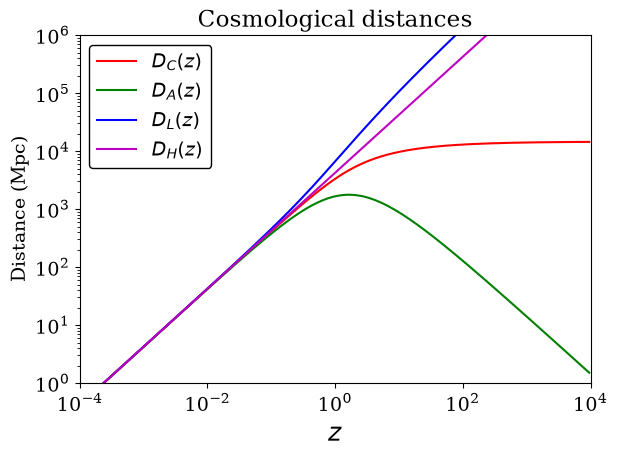

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad

# Disable external LaTeX // To fix the error of labels in the final graph 
plt.rcParams['text.usetex'] = False
plt.close('all')

# Integrand 1/E(z) for comoving distance, where E(z) is dimensionless
# Hubble constant at redshift z (eq. 14 in Hogg 2000)
def ez(z, om):
    return 1.0 / np.sqrt(om * np.power(1.0 + z, 3.0) + 1.0 - om)

# Comoving distance (eq. 15 in Hogg 2000)
def dc(z, om, h0):
    return 299792.458 * quad(ez, 0.0, z, args=(om))[0] / h0

# Angular diameter distance (eq. 18 in Hogg 2000)
def da(z, om, h0):
    return dc(z, om, h0) / (1.0 + z)

# Luminosity distance (eq. 21 in Hogg 2000)
def dl(z, om, h0):
    return (1.0 + z) * dc(z, om, h0)

# Hubble distance DH(z) = c * z / H_0
def dh(z, h0):
    return 299792.458 * z / h0

# Hubble constant and Omega_M
h0 = 71.0
om = 0.27

# Cosmological distances as functions of redshift z (In arrays, to take some value and take a range with some steps) 
# We get the values of the diferent distances a different values 
zz = [np.power(10.0, x) for x in np.arange(-4.0, 4.0, 0.02)]
dcz = [dc(z, om, h0) for z in zz] 
daz = [da(z, om, h0) for z in zz]
dlz = [dl(z, om, h0) for z in zz]
dhz = [dh(z, h0) for z in zz]


# Plot the results
plt.plot(zz, dcz, 'r-', label='$D_C(z)$')
plt.plot(zz, daz, 'g-', label='$D_A(z)$')
plt.plot(zz, dlz, 'b-', label='$D_L(z)$')
plt.plot(zz, dhz, 'm-', label='$D_H(z)$')
plt.xscale('log')
plt.yscale('log')
plt.xlim(1.0e-4, 1.0e4)
plt.ylim(1.0, 1.0e6)
plt.xlabel('$z$', fontsize=18)
plt.ylabel('Distance (Mpc)')
plt.legend(loc='upper left')
plt.title('Cosmological distances')

# Save the figure
plt.tight_layout()
plt.savefig('cosm_dist.jpg', dpi=300, bbox_inches='tight')
plt.show()


# Exercise 4

Write a Python script which computes angular diameter distance
between two objects at redshifts z1 and z2 in the case of a flat
(Ωk = 0) cosmological model with H0 = 71/km/s/Mpc and ΩM = 0.27,
and use it to reconsider the exercise with an alien astronomer by
calculating all three angular diameter distances: DA (0, za) - between
you and an alien at redshift za = 1, DA(0, zq) - between you and a
quasar at zq = 2 and DA (za, zq) - between alien and quasar.

In [1]:
#!/usr/bin/env python3

import numpy as np
from scipy.integrate import quad

# Integrand for comoving distance
def ez(z, om):
    return 1.0 / np.sqrt(om * np.power(1.0 + z, 3.0) + 1.0 - om)

# Comoving distance (eq. 15 in Hogg 2000)
def dc(z, om, h0):
    return 299792.458 * quad(ez, 0.0, z, args=(om))[0] / h0

# Angular diameter distance (eq. 18 in Hogg 2000)
def da(z, om, h0):
    return dc(z, om, h0) / (1.0 + z)

# Angular diameter distance between two objects
# at redshifts z1 and z2 (eq. 19 in Hogg 2000)
def da12(z1, z2, om, h0):
    return (dc(z2, om, h0) - dc(z1, om, h0)) / (1.0 + z2)

z1 = float(input('Enter the 1st redshift: '))
z2 = float(input('Enter the 2nd redshift: '))
h0 = float(input('Enter the Hubble constant: '))
om = float(input('Enter the Omega_matter: '))

print('\nAngular diameter distance DA(0,z1) = {0:.1f} Mpc'.format(da(z1, om, h0)))
print('Angular diameter distance DA(0,z2) = {0:.1f} Mpc'.format(da(z2, om, h0)))
print('Angular diameter distance  DA(z1,z2) = {0:.1f} Mpc'.format(da12(z1, z2, om, h0)))


Enter the 1st redshift:  1
Enter the 2nd redshift:  2
Enter the Hubble constant:  71
Enter the Omega_matter:  0.27



Angular diameter distance DA(0,z1) = 1658.7 Mpc
Angular diameter distance DA(0,z2) = 1748.4 Mpc
Angular diameter distance  DA(z1,z2) = 642.6 Mpc
